# Batch implementation

This is a reimplementation of torch_linear.ipynb computing SGD on batches. The mathematics isn't really that much more difficult. 

Useful commands Hidden
$$
\newcommand{\pd}[2]{\frac{\partial #1}{\partial #2}}
$$

## Derivation of vjp for mm, add.. 


### Forward

Layer 1

We typically treat W as (out_dim, in_dim), which is fine when x is a vector. However, with batched inputs, we want each row to correspond to a different item in the batch:
$X_{ik}$ - each row is an example - i increments over the batch.

Previously we had.
$$
\begin{equation}
s_{i} = W_{ij} x_j
\end{equation}
$$

Now batch aware (i is the batch index):
$$
\begin{aligned}
  s_{ij} &=  W_{jk} X_{ik} \\
  s_{ij} &=  W^T_{kj} X_{ik} \\
  s_{ij} &=  X_{ik} W^T_{kj}  \\
\end{aligned}
$$

In non-index notation, this is:
$$
\begin{equation}
  \bf{s}  := \bf{X} @ \bf{W}^T 
\end{equation}
$$
Broadcasting:

$$
\begin{equation}
u_{ij} = s_{ij} + b_{j}
\end{equation}
$$
Activation

$$
z_{ij} = \sigma(u_{ij})
$$

Layer 2

B is actually a vector for univariate regression. But we write it in general multivariate here. 
$$
\begin{aligned}
t_{ij} &= z_{ik} B^T_{kj} \\
\hat{y}_{ij} &= t_{ij} + c_j
\end{aligned}
$$

Loss (where i is the example and j is the number of outputs). Remember that y is the actual value and yhat is the prediction. Below it is written in general form for multi variable output. I.e. regression in multiple dimensions (predicting 2 dimensions for instance. )

$$
l = 0.5\,(\hat{y}_{ij} - y_{ij})(\hat{y}_{ij} - y_{ij})
$$




### Backward
Sequence of steps:

Keeping the outer (upstream) gradient on the left. (This doesn't really matter when using index notation)

$$
\frac{dl}{d\hat{y}_{kl}} = \frac{1}{2NM} \pd{}{\hat{y}_{kl}}(\hat{y}_{ij} - y_{ij})^2 = \frac{1}{NM} \delta_{ik}\delta_{jl} (\hat{y}_{ij} - y_{ij}) = \frac{1}{NM}(\hat{y}_{kl} - y_{kl}) = e_{kl}
$$

2nd Add, $ \hat{y}_{ij} = t_{ij} + c_j$
$$
\pd{l}{t_{ij}} = \pd{l}{\hat{y}_{kl}} \pd{\hat{y}_{kl}}{t_{ij}}, \quad \pd{l}{c_j} = \pd{l}{\hat{y}_{kl}} \pd{\hat{y}_{kl}}{c_j} 
$$

$$
\pd{l}{\hat{y}_{kl}} = e_{kl}
$$

$$
\pd{l}{t_{ij}} = e_{ij}, \quad \pd{l}{c_j} = \frac{1}{NM} (\hat{y}_{kj} - y_{kj}) = \sum_k^N  e_{kj}
$$

2nd Matmul, $t_{ij} = z_{ik} B^{T}_{kj}$
$$
\pd{l}{B_{ij}} = \pd{l}{t_{kl}} \pd{t_{kl}}{B_{ij}}, \quad \pd{l}{z_{ij}} = \pd{l}{t_{kl}} \pd{t_{kl}}{z_{ij}}
$$

$$
\pd{l}{t_{kl}} = e_{kl}, \quad \pd{t_{kl}}{B_{ij}} = z_{km}\pd{B_{ml}^T}{B_{ij}} = z_{km}\delta_{il}\delta_{jm}
$$

$$
\pd{l}{B_{ij}} = e_{ki} z_{kj}, \quad \pd{l}{z_{ij}} = e_{il}B_{lj}
$$



Propagate through activation function, $z_{ij} = \sigma(u_{ij})$
$$
\pd{l}{u_{ij}} = \pd{l}{z_{kl}}\pd{z_{kl}}{u_{ij}}
$$

$$
\pd{l}{u_{ij}} = e_{km}{B_{ml}}\sigma_{kl}(1-\sigma_{kl})\delta_{ik}\delta_{jl} = e_{im}{B_{mj}}\sigma_{ij}(1-\sigma_{ij})
$$

1st Add, $u_{ij} = s_{ij} + b_j$
$$
\pd{l}{s_{ij}} = \pd{l}{u_{kl}} \pd{u_{kl}}{s_{ij}} , \quad \pd{l}{b_j} = \pd{l}{u_{kl}} \pd{u_{kl}}{b_j}
$$

$$
\pd{l}{s_{ij}} = \pd{l}{u_{kl}} \delta_{ik}\delta_{jl}, \quad \pd{l}{b_j} = \pd{l}{u_{kl}} \delta_{jl}
$$

1st Matmul, $s_{ij} = X_{ik} W_{kj}^T$
$$
\pd{l}{W_{ij}} = \pd{l}{s_{kl}}\pd{s_{kl}}{W_{ij}}, \quad \pd{l}{X_{ij}} is unused 
$$

$$
\pd{l}{W_{ij}} = \pd{l}{s_{kl}} X_{km} \pd{W_{ml}^T}{W_{ij}} = \pd{l}{s_{kl}} X_{km} \delta_{il} \delta_{jm} = \pd{l}{s_{ki}} X_{kj}
$$


# This is now ready to implement in torch

Some ideas:
- Fit a 2D function (this is still only scalar output and I want to predict two values using regression)
- Remember that previously I created a set of vjps for addition and 

In [1]:
import torch
import numpy as np
import random

# ensure determinism
np.random.seed(0)
random.seed(0)
torch.manual_seed(0)

# W_true = torch.tensor([[2.0, -1], [0.5, 3.0], [-1.5, 1.0]])
W_true = torch.tensor([[2.0, 0.5, -1.5], [-1.0, 3.0, 1.0]], dtype=torch.float64)
B_true = torch.tensor([1.0, -2.0], dtype=torch.float64)
X = torch.tensor([[1.0, 2.0, 0.0], [-1.0, 0.0, 3.0]], dtype=torch.float64)

print(X.shape, W_true.shape, B_true.shape)
# Y = X @ W_
# we tend to represent the W as follows:

Y_mm = X @ W_true.T
Y_add = Y_mm + B_true
print(f"Y_mm\n{Y_mm}\n", f"Y_add\n{Y_add}")
print("each row corresponds to an example, so broadcasting is correct")
# Q. why is this the default behaviour of broadcasting in torch?


torch.Size([2, 3]) torch.Size([2, 3]) torch.Size([2])
Y_mm
tensor([[ 3.0000,  5.0000],
        [-6.5000,  4.0000]], dtype=torch.float64)
 Y_add
tensor([[ 4.0000,  3.0000],
        [-5.5000,  2.0000]], dtype=torch.float64)
each row corresponds to an example, so broadcasting is correct


# Test problem: Rotations

Given $ \mathbf{x} \in \mathbb{R}^2 $ and $\theta \in (0, 2 \pi)$ we must learn the 2D rotation matrix:
$$
\mathbf{y} = \mathbf{R} \mathbf{x} = \begin{pmatrix} cos\theta & -sin\theta \\ sin\theta & cos\theta \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix}
$$

The cell below prepares the dataset 


In [ ]:
import numpy as np
# Generate some example data
# create some random batch


def create_XY_data(n_examples):
    torch.manual_seed(0)
    # n_feats = 3
    # n_outputs = 2
    # train_set = torch.rand((n_examples, n_feats), dtype=torch.float64)
    # X = torch.rand(size=(n_examples, n_feats), dtype=torch.float64)

    x1 = torch.rand(n_examples, dtype=torch.float64)
    x2 = torch.rand(n_examples, dtype=torch.float64)
    theta = torch.rand(n_examples, dtype=torch.float64) * 2 * torch.pi

    def rotation(theta):
        return torch.tensor(
            [
                [torch.cos(theta), -torch.sin(theta)],
                [torch.sin(theta), torch.cos(theta)],
            ]
        )

    # rotation(theta)
    rotations = torch.tensor(
        list(map(lambda t: [[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]], theta)),
        dtype=torch.float64,
    )

    # stack it in column direction
    x1x2 = torch.stack((x1, x2), dim=1)
    print(rotations.shape, x1x2.unsqueeze(2).shape)

    # Multiplying the rotation matrix by the inputs in vectorised way:
    # Attempt 1: Using bmm
    # we need to unsqueeze here for bmm to work - this adds another dimension so
    # the batch matrix multiplication works
    Y = torch.bmm(rotations, x1x2.unsqueeze(2))
    # Attempt 2: Using einsum
    ## or since rotations is (10, 2, 2) and x1x2.unsqueeze is (10, 2)
    Y = torch.einsum("bik, bk -> bi", rotations, x1x2.squeeze())
    # Attempt 3: Manual slow way
    Y = torch.stack(
        [rotation(t) @ torch.stack([x, y], dim=0) for t, x, y in zip(theta, x1, x2)],
        dim=0,
    )
    return torch.stack((x1, x2, theta), dim=1), Y


In [101]:
torch.manual_seed(0)
from torch.nn.functional import sigmoid


def initialise_params(X):
    in_feats = X.shape[1]
    out_feats = 32
    W = 0.1 * torch.rand((out_feats, in_feats), dtype=torch.float64)
    W.requires_grad = True
    b = 0.1 * torch.rand((out_feats), dtype=torch.float64)
    b.requires_grad = True

    inh_feats = out_feats
    outh_feats = 2

    B = 0.1 * torch.rand((outh_feats, inh_feats), dtype=torch.float64)
    B.requires_grad = True
    c = 0.1 * torch.rand((outh_feats), dtype=torch.float64)
    c.requires_grad = True

    return ((W, b), (B, c))


def vjp_mse(yhat, Y, dldp):
    return 1 / (Y.shape[0] * Y.shape[1]) * dldp * (yhat - Y)


def vjp_add(a, b, dldp):
    dlda = dldp
    dldb = torch.sum(dldp, dim=0)
    return dlda, dldb


def vjp_mm(a, b, dldp):
    dlda = dldp @ b
    dldb = dldp.T @ a
    return dlda, dldb


def vjp_sigmoid(a, dldp):
    # print(dldp.shape, a.shape)
    dlda = dldp * sigmoid(a) * (1 - sigmoid(a))
    return dlda


def ffn(params, X, Y):
    ((W, b), (B, c)) = params

    s = X @ W.T
    u = s + b

    # print(u.shape)
    z = sigmoid(u)

    t = z @ B.T
    y = t + c
    lo = 1 / (2 * y.shape[0] * y.shape[1]) * torch.sum((y - Y) * (y - Y))
    assert lo.shape == torch.Size([])
    return lo


def fwdbck(W, X, Y):
    ((W, b), (B, c)) = W

    # forward
    s = X @ W.T
    u = s + b
    z = sigmoid(u)
    t = z @ B.T
    y = t + c

    # compute loss
    lo = 1.0 / (2 * y.shape[0] * y.shape[1]) * torch.sum((y - Y) * (y - Y))
    assert lo.shape == torch.Size([])

    # backward
    dlossdloss = 1
    # this propagates the error (not the loss)
    dldyhat = vjp_mse(y, Y, dldp=dlossdloss)  ## 2nd order tensor
    dldt, dldc = vjp_add(a=t, b=c, dldp=dldyhat)  ## 2nd order, 1st order

    dldz, dldB = vjp_mm(a=z, b=B, dldp=dldt)
    # print(dldz.shape, z.shape)
    dldu = vjp_sigmoid(a=u, dldp=dldz)

    dlds, dldb = vjp_add(a=s, b=b, dldp=dldu)
    dldX, dldW = vjp_mm(a=X, b=W, dldp=dlds)

    # all gradients for all params computed, ready to return
    return ((dldW, dldb), (dldB, dldc)), lo


# Now test on some small sample data
This calls create_XY_data above and runs a fwdbck step (reverse mode autograd) to compute gradients of dL/dW1, dL/db1, dL/dW2 and dL/db2. 

We check to see how close gradients are to the actual loss.backward

In [98]:
def test_single_step(X_train, Y_train):
    params = initialise_params(X_train)
    loss = ffn(params, X_train, Y_train)
    loss.backward()
    ((W, b), (B, c)) = params
    # W_new = fwdbck(W, X, Y)
    # Verify against PyTorch's native autograd:
    grads, loss = fwdbck(params, X_train, Y_train)
    (dldW, dldb), (dldB, dldc) = grads

    # print(W)
    # assert torch.allclose
    print(type(W.grad), type(dldW))
    print(W.shape, dldW.shape)

    assert torch.allclose(dldW, W.grad)
    assert torch.allclose(dldb, b.grad)
    assert torch.allclose(dldB, B.grad)
    assert torch.allclose(dldc, c.grad)


tempX, tempY = create_XY_data(10)
test_single_step(tempX, tempY)

torch.Size([10, 2, 2]) torch.Size([10, 2, 1])
torch.Size([10, 32]) torch.Size([10, 32])
<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.Size([32, 3]) torch.Size([32, 3])


/var/folders/_p/mcyznlbn3_b0cfymc42573mw0000gn/T/ipykernel_54517/2693241795.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  list(map(lambda t: [[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]], theta)),


# Train model 

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)

# initialisation using random fn
X, Y = create_XY_data(10000)
# print("X.shape: ", X.shape, " Y.shape: ", Y.shape)
# hyperparameters
lr = 1e-3
train_mse_list = []

params = initialise_params(X)
((W, b), (B, c)) = params

print("W.shape ", W.shape)

# TODO: improve this code to make it more maintainable
# We check with .backward so previously we needed gradients to be tracked
# Since we're doing it manually this is no longer the case: 
W.requires_grad = False
b.requires_grad = False
B.requires_grad = False
c.requires_grad = False

# set requires_grad = False as we aren't backpropagating
dataset = TensorDataset(X, Y)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)
loss_train_epoch = []
loss_train_batch_all = []

for epoch in range(0, 10):
    # iterate over dataset
    loss_train_batch = []
    for batch_idx, (batch_x, batch_y) in enumerate(dataloader):

        
        # loop over batches
        # for b in batches:
        # compute gradients and loss

        grads, lo = fwdbck(params, batch_x, batch_y)
        loss_train_batch.append(lo.item())
        loss_train_batch_all.append(lo.item())
        # print(len(grads))
        (dldW, dldb), (dldB, dldc) = grads

        W -= lr * dldW
        b -= lr * dldb
        B -= lr * dldB
        c -= lr * dldc
        params = ((W, b), (B, c))

    
    loss_train_epoch.append(sum(loss_train_batch)/len(loss_train_batch))


/var/folders/_p/mcyznlbn3_b0cfymc42573mw0000gn/T/ipykernel_54517/2693241795.py:25: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  list(map(lambda t: [[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]], theta)),


torch.Size([10000, 2, 2]) torch.Size([10000, 2, 1])
W.shape  torch.Size([32, 3])


In [132]:
print(dldW.shape)
print(W.shape)

torch.Size([32, 3])
torch.Size([32, 3])


In [133]:
print(loss_train_epoch)

[0.3936804756076253, 0.20627278979167163, 0.17440998315642245, 0.1688555830780237, 0.16792792613775773, 0.16767855875011528, 0.16734470438357504, 0.16761817171743418, 0.16749974076472096, 0.16741142785902727]


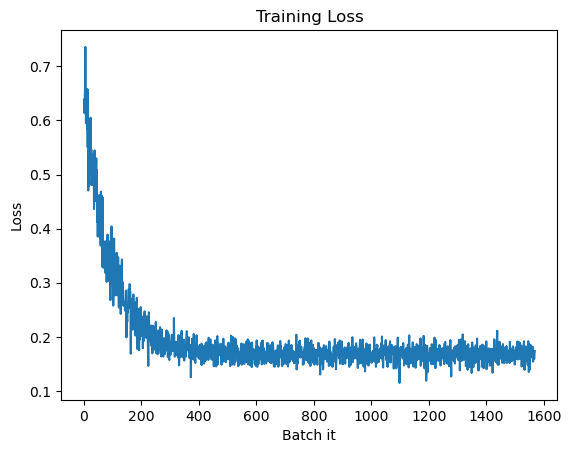

In [134]:
import matplotlib.pyplot as plt
plt.plot(loss_train_batch_all)
plt.xlabel("Batch it")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

In [ ]:
# Residuals

